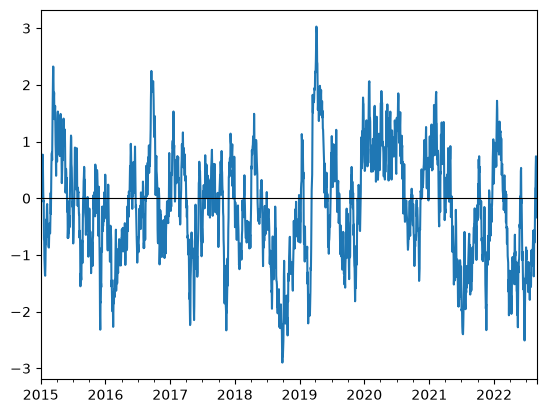

In [1]:
from closed_form import simulate_ou
import matplotlib.pyplot as plt

x = simulate_ou()
x.plot(); plt.axhline(0, color="k", lw=0.8); plt.show()

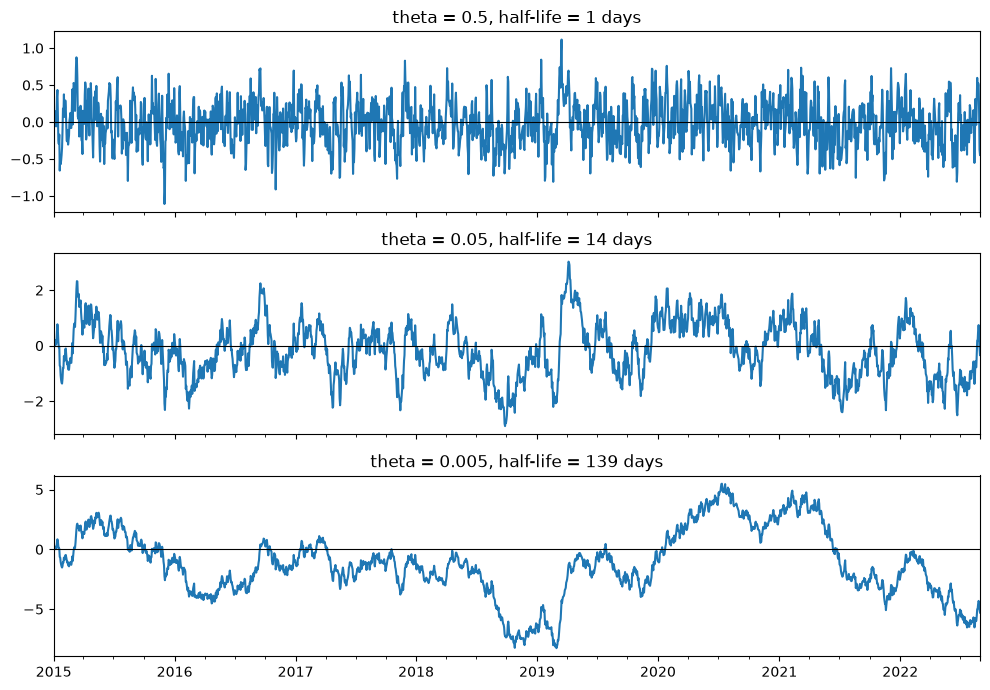

In [4]:
import numpy as np
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, th in zip(axes, [0.5, 0.05, 0.005]):
    simulate_ou(theta=th).plot(ax=ax, title=f"theta = {th}, half-life = {np.log(2)/th:.0f} days")
    ax.axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

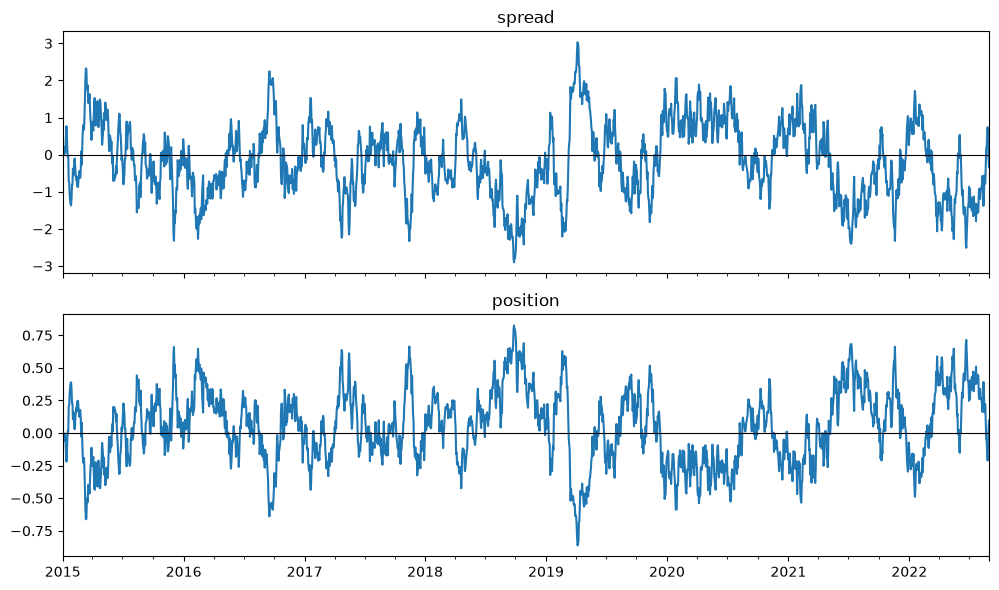

In [5]:
import importlib, closed_form; importlib.reload(closed_form)
from closed_form import simulate_ou, closed_form_positions

x = simulate_ou()
w = closed_form_positions(x, theta=0.05, mu=0.0, sigma=0.3)

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
x.plot(ax=axes[0], title="spread"); axes[0].axhline(0, color="k", lw=0.8)
w.plot(ax=axes[1], title="position"); axes[1].axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

Sharpe: 2.42   total P&L: 24.95   turnover: 134.5


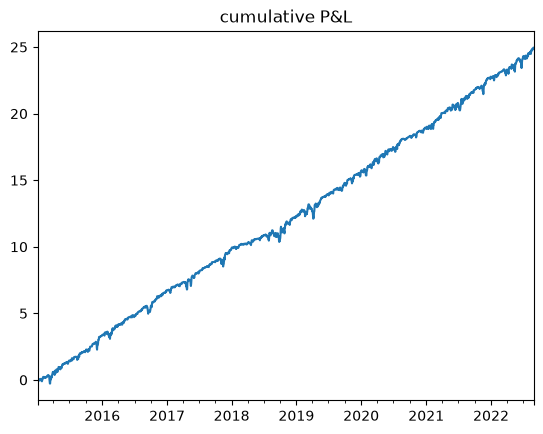

In [ ]:
pnl = w.shift(1) * x.diff()
pnl = pnl.dropna()

sharpe = pnl.mean() / pnl.std() * np.sqrt(252)
turnover = w.diff().abs().sum()
print(f"Sharpe: {sharpe:.2f}   total P&L: {pnl.sum():.2f}   turnover: {turnover:.1f}")

pnl.cumsum().plot(title="cumulative P&L"); plt.show()

In [7]:
for c in [0, 0.05, 0.1, 0.2]:
    net = pnl - c * w.diff().abs().reindex(pnl.index)
    s = net.mean() / net.std() * np.sqrt(252)
    print(f"fee {c:.2f}:  net P&L {net.sum():6.2f}   Sharpe {s:.2f}")

fee 0.00:  net P&L  24.95   Sharpe 2.42
fee 0.05:  net P&L  18.23   Sharpe 1.78
fee 0.10:  net P&L  11.50   Sharpe 1.13
fee 0.20:  net P&L  -1.95   Sharpe -0.19
